# Wairagkar 2025: training a brain-to-voice (neural → LPCNet) decoder

Maps the **512-d neural features** (spike-band power + threshold crossings) to the **LPCNet acoustic target** (20 features: 18 Bark-cepstral coefficients, pitch period, pitch correlation) on a shared 100 Hz grid, the target the paper's decoders trained on.

One evaluation session (`t15_day188`), using the source's own partition through `AssignSourceSplit`: the model trains on the session's `Training data` trials and is validated on its closed-loop `Evaluation trial` rows, the trials the paper reports on. The syllable-aligned target is used because that is the variant the paper's decoders trained on after day 25. The decoder is offline, its symmetric 7-tap convolution sees 30 ms into the future, unlike the paper's causal model, and same-day training data is a retrospective stand-in for the paper's protocol of training on every earlier session.

The setup cell builds the Study and calls `download()`, which fetches the data on the first run and returns immediately once the success file exists. It needs a Dryad API key, exported as `NEURALFETCH_DRYAD_TOKEN` or saved in a local `.env` file.

In [1]:
from dotenv import load_dotenv
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

import neuralset as ns
import pandas as pd
from neuralshed import transforms
from neuralshed.extractors import NeuralFeatureExtractor, BehavioralSeriesExtractor
from neuralshed.datasets.wairagkar_2025 import study
from neuralshed.datasets.utils import dataset_dir

torch.manual_seed(0)

# reads ./.env into os.environ
load_dotenv()

root = dataset_dir("wairagkar_2025") / "data"
s = study.Wairagkar2025Brain2Voice(path=root)
s.download()

FS = 100.0      # 100 Hz
WIN_S = 2.0     # 2 s windows (T=200)
STRIDE_S = 1.0  # 1 s stride
N_FEATS = 20
SESSION = "t15_day188"                               # one evaluation session, attempted speech only
TARGET = "lpcnet_syllable_aligned"                   # the variant the paper's decoders trained on
CACHE_DIR = dataset_dir("wairagkar_2025") / "cache"  # extractor disk cache

chain = ns.Chain(steps={
    "study": study.Wairagkar2025Brain2Voice(
        path=root,
        query=f"session == '{SESSION}' and task_condition == 'attempted'",
    ),
    "split": transforms.AssignSourceSplit(mapping={"train": "train", "eval": "val"}),
})
events = chain.run()

sentences = events[events.type == "Sentence"]
print("trials:", events.timeline.nunique(), "| types:", events.type.value_counts().to_dict())
display(pd.crosstab(sentences.trial_description, sentences.split, margins=True))

train_cues = set(sentences[sentences.split == "train"].text)
n_shared = int(sentences[sentences.split == "val"].text.isin(train_cues).sum())
print("val cues that also occur as train cues:", n_shared)

2026-10-15 12:10:08 - INFO - neuralset.events.study:463 - Success: Study downloaded to /Volumes/seagate_0/tether/datasets/wairagkar_2025/data/Wairagkar2025Brain2Voice.


2026-10-15 12:10:18 - INFO - neuralset.events.study:85 - Permissions set for /Volumes/seagate_0/tether/datasets/wairagkar_2025/data/Wairagkar2025Brain2Voice (skipped 0 non-owned items).


trials: 301 | types: {'Word': 1812, 'AcousticFeatures': 602, 'BandPower': 301, 'SpikeCounts': 301, 'Sentence': 301}


split,train,val,All
trial_description,,,
Evaluation trial,0,132,132
Evaluation trial (free response),0,7,7
Training data,162,0,162
All,162,139,301


val cues that also occur as train cues: 0


## 1. Segment the trials into windows

Trigger on the per-trial `Sentence` and slide fixed 2 s windows with a 1 s stride. `input` concatenates the `BandPower` + `SpikeCounts` streams (512 channels, native order). `target` reads the syllable-aligned `AcousticFeatures` row at the same 100 Hz rate, selected by `feature`.

In [2]:
cache = dict(folder=CACHE_DIR, keep_in_ram=False)   # disk cache
segmenter = ns.dataloader.Segmenter(
    extractors={
        "input": NeuralFeatureExtractor(
            target_unit="native",
            frequency=FS,
            aggregation="cat",
            infra=cache,
        ),
        "target": BehavioralSeriesExtractor(
            event_types="AcousticFeatures",
            query=f"feature == '{TARGET}'",
            frequency=FS,
            infra=cache,
        ),
    },
    trigger_query="type == 'Sentence'",
    start=0.0,
    duration=WIN_S,
    stride=STRIDE_S,
)
ds = segmenter.apply(events)
ds.prepare()
print(ds)

2026-10-15 12:10:21 - INFO - neuralset.dataloader:222 - Preparing extractor: NeuralFeatureExtractor


2026-10-15 12:10:22 - INFO - neuralset.dataloader:222 - Preparing extractor: BehavioralSeriesExtractor


SegmentDataset(3598 segments, 2.00s, extractors: input, target)


## 2. Materialize and split by the source's partition

Every window inherits the `split` of its trial, so the session's training trials form the training set and its closed-loop evaluation trials the validation set. No window crosses a trial, and no validation cue occurs among the training cues.

In [3]:
batch = ds.load_all()
X = batch.data["input"].float()   # (N, 512, T)
Y = batch.data["target"].float()  # (N, 20, T)

tl2split = dict(zip(events["timeline"], events["split"]))
tl2trial = dict(zip(events["timeline"], events["trial_id"].astype(int)))
seg_split = np.array([tl2split[seg.timeline] for seg in batch.segments])
seg_trial = np.array([tl2trial[seg.timeline] for seg in batch.segments])

tr = torch.tensor(seg_split == "train")
va = torch.tensor(seg_split == "val")
Xtr = X[tr]
Ytr = Y[tr]
Xva = X[va]
Yva = Y[va]

n_train_trials = len(np.unique(seg_trial[tr.numpy()]))
n_val_trials = len(np.unique(seg_trial[va.numpy()]))
print("X", tuple(X.shape), "| Y", tuple(Y.shape))
print("train/val windows:", int(tr.sum()), "/", int(va.sum()))
print("train/val trials:", n_train_trials, "/", n_val_trials)

X (3598, 512, 200) | Y (3598, 20, 200)
train/val windows: 1746 / 1852
train/val trials: 162 / 139


## 3. Normalize (per-channel input, per-feature target), statistics from the training windows only

In [4]:
x_mu = Xtr.mean((0, 2), keepdim=True)
x_sd = Xtr.std((0, 2), keepdim=True) + 1e-6
y_mu = Ytr.mean((0, 2), keepdim=True)
y_sd = Ytr.std((0, 2), keepdim=True) + 1e-6


def nx(x):
    return (x - x_mu) / x_sd


def ny(y):
    return (y - y_mu) / y_sd


Xtr_n = nx(Xtr)
Ytr_n = ny(Ytr)
Xva_n = nx(Xva)
Yva_n = ny(Yva)

## 4. A simple seq2seq decoder

A 1×1 bottleneck, a temporal convolution (kernel 7, symmetric padding) and a 1×1 readout. The symmetric kernel gives it 30 ms of lookahead, so it is an offline decoder.

In [5]:
class VoiceDecoder(nn.Module):
    def __init__(self, c_in, c_out, hidden=96, k=7, p_drop=0.2):
        super().__init__()
        pad = k // 2
        self.net = nn.Sequential(
            nn.Conv1d(c_in, hidden, 1),  # 1x1 bottleneck
            nn.ReLU(),
            nn.Dropout(p_drop),
            nn.Conv1d(hidden, hidden, k, padding=pad),  # temporal convolution
            nn.ReLU(),
            nn.Dropout(p_drop),
            nn.Conv1d(hidden, c_out, 1),  # 1x1 readout
        )

    def forward(self, x):
        return self.net(x)  # (B, c_out, T)


model = VoiceDecoder(X.shape[1], Y.shape[1])
print(model)

VoiceDecoder(
  (net): Sequential(
    (0): Conv1d(512, 96, kernel_size=(1,), stride=(1,))
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Conv1d(96, 96, kernel_size=(7,), stride=(1,), padding=(3,))
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Conv1d(96, 20, kernel_size=(1,), stride=(1,))
  )
)


## 5. Train

In [6]:
train_loader = DataLoader(TensorDataset(Xtr_n, Ytr_n), batch_size=128, shuffle=True)
opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
loss_fn = nn.MSELoss()

N_EPOCHS = 30
best_val = float("inf")
best_state = None

for epoch in range(N_EPOCHS):
    model.train()
    running = 0.0
    n_batches = 0
    for xb, yb in train_loader:
        opt.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        opt.step()
        running += loss.item()
        n_batches += 1

    model.eval()
    with torch.no_grad():
        val_loss = loss_fn(model(Xva_n), Yva_n).item()

    if val_loss < best_val:
        best_val = val_loss
        best_state = {k: v.clone() for k, v in model.state_dict().items()}

    if (epoch + 1) % 10 == 0:
        print(f"epoch {epoch + 1:2d}  train MSE {running / n_batches:.3f}  val MSE {val_loss:.3f}  (best {best_val:.3f})")

model.load_state_dict(best_state)
print("best val MSE (normalized):", round(best_val, 3))

epoch 10  train MSE 0.731  val MSE 0.785  (best 0.781)


epoch 20  train MSE 0.645  val MSE 0.804  (best 0.781)


epoch 30  train MSE 0.598  val MSE 0.819  (best 0.781)
best val MSE (normalized): 0.781


## 6. Evaluate: correlation and R² per LPCNet feature

Predictions are mapped back to LPCNet units. Both metrics are dimensionless and are computed on the session's closed-loop evaluation trials, which also chose the checkpoint, so they are validation numbers rather than a held-out test.

In [7]:
model.eval()
with torch.no_grad():
    pred = model(Xva_n) * y_sd + y_mu  # back to LPCNet units

P = pred.permute(1, 0, 2).reshape(N_FEATS, -1).numpy()
T = Yva.permute(1, 0, 2).reshape(N_FEATS, -1).numpy()

corr = np.array([np.corrcoef(P[i], T[i])[0, 1] for i in range(N_FEATS)])
ss_res = ((T - P) ** 2).sum(1)
ss_tot = ((T - T.mean(1, keepdims=True)) ** 2).sum(1) + 1e-9
r2 = 1 - ss_res / ss_tot

print(f"per-feature corr : mean {corr.mean():.3f}  (min {corr.min():.3f}, max {corr.max():.3f})")
print(f"per-feature R2   : mean {r2.mean():.3f}")
print(f"bfcc_0 (overall energy): corr {corr[0]:.3f}  R2 {r2[0]:.3f}")

per-feature corr : mean 0.354  (min 0.120, max 0.780)
per-feature R2   : mean 0.153
bfcc_0 (overall energy): corr 0.780  R2 0.606


## 7. Decoded vs true target on one held-out trial

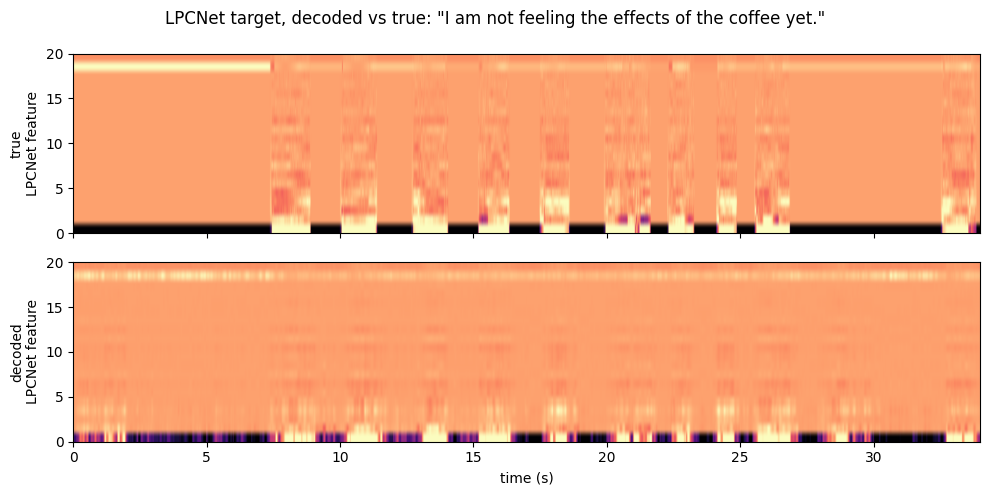

In [8]:
val_trials = np.unique(seg_trial[va.numpy()])
pick = max(val_trials, key=lambda g: int((seg_trial == g).sum()))  # longest validation trial
idx = np.where(seg_trial == pick)[0]

with torch.no_grad():
    pred_trial = (model(nx(X[idx])) * y_sd + y_mu).numpy()
true_trial = Y[idx].numpy()

# rebuild the trial from the first stride of every window
step = int(STRIDE_S * FS)
Pcat = np.concatenate([pred_trial[k, :, :step] for k in range(len(idx))], axis=1)
Tcat = np.concatenate([true_trial[k, :, :step] for k in range(len(idx))], axis=1)
tt = np.arange(Pcat.shape[1]) / FS

is_pick = events.trial_id.astype(int) == pick
sentence_row = events[is_pick & (events.type == "Sentence")].iloc[0]

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
vmin = np.percentile(Tcat, 2)
vmax = np.percentile(Tcat, 98)
for ax, M, lab in zip(axes, [Tcat, Pcat], ["true", "decoded"]):
    ax.imshow(
        M,
        aspect="auto",
        origin="lower",
        cmap="magma",
        vmin=vmin,
        vmax=vmax,
        extent=[0, tt[-1], 0, N_FEATS],
    )
    ax.set_ylabel(f"{lab}\nLPCNet feature")
axes[-1].set_xlabel("time (s)")
fig.suptitle(f'LPCNet target, decoded vs true: "{sentence_row.text}"')
plt.tight_layout()
plt.show()